# Ekstrakcja cech z segmentów sygnału EKG

## Cel analizy

Celem tego etapu jest przekształcenie segmentów sygnału elektrokardiograficznego w wektory cech opisujące właściwości poszczególnych uderzeń serca. Uzyskane reprezentacje zostaną wykorzystane jako dane wejściowe modeli One-Class Support Vector Machine (OCSVM) oraz Support Vector Machine (SVM).

W przypadku OCSVM zadaniem będzie binarne wykrywanie anomalii, natomiast SVM zostanie wykorzystany do klasyfikacji wieloklasowej uderzeń według grup N, S, V i F.

## Dane wejściowe

Dane pochodzą z bazy MIT-BIH Arrhythmia Database. W poprzednich etapach przeprowadzono filtrację sygnału EKG za pomocą filtra pasmowoprzepustowego Butterwortha o częstotliwościach granicznych 0,5–40 Hz oraz segmentację na podstawie lokalizacji uderzeń zapisanych w adnotacjach.

Każdy segment zawiera 256 próbek sygnału zarejestrowanego z częstotliwością 360 Hz:

- 100 próbek przed lokalizacją adnotacji,
- 156 próbek od lokalizacji adnotacji.

Długość pojedynczego segmentu wynosi około 0,711 s.

Dane zostały wcześniej podzielone na zbiory treningowy, walidacyjny i testowy z zachowaniem niezależności grup pacjentów. Ekstrakcja cech będzie przeprowadzana dla każdego z tych zbiorów, bez ponownego losowania obserwacji.

## Założenia ekstrakcji cech

W analizie zostaną wykorzystane trzy grupy cech:

### 1. Cechy statystyczne i amplitudowe

Opisują rozkład wartości amplitudy, zmienność oraz ogólne właściwości sygnału w obrębie pojedynczego segmentu.

Do tej grupy należą:

- średnia arytmetyczna,
- odchylenie standardowe,
- mediana,
- rozstęp międzykwartylowy,
- skośność,
- kurtoza,
- wartość minimalna,
- wartość maksymalna,
- rozstęp amplitudy,
- wartość skuteczna RMS ($RMS=\sqrt{\frac{1}{N}\sum_{i=1}^Nx_i^2}$).

### 2. Cechy opisujące energię i zmienność sygnału

Pozwalają scharakteryzować intensywność zmian amplitudy oraz lokalną dynamikę przebiegu EKG.

Do tej grupy należą:

- energia sygnału ($E=\sum_{i=1}^Nx_i^2$),
- długość przebiegu (*waveform length*) ($WL=\sum_{i=1}^{N-1}|x_{i+1}-x_i|$),
- maksymalna bezwzględna różnica między kolejnymi próbkami ($D_{max}=\max_{1\leq i<N}|x_{i+1}-x_i|$).

### 3. Cechy morfologiczne i rytmiczne

Dostarczają informacji o kształcie zespołu QRS oraz odstępach czasowych pomiędzy kolejnymi uderzeniami serca.

Do tej grupy należą:
- max nachylenie ($S_{QRS}=\max_{70\leq i<144}|x_{i+1}-x_i|$),
- pole pod zespołem QRS ($A_{QRS}=\frac{1}{FS}\sum_{i=70}^144|x_i-b|$, gdzie b - lokalna linia odniesienia),
- poprzedni odstęp RR,
- następny odstęp RR,
- względny poprzedni odstęp RR.

Cechy rytmiczne będą wyznaczane na podstawie lokalizacji uderzeń w oryginalnych adnotacjach MIT-BIH, z zachowaniem ich kolejności w poszczególnych nagraniach.

## Przygotowanie danych do modelowania

Ekstrakcja cech zostanie wykonana osobno dla zbiorów treningowego, walidacyjnego i testowego.

Na tym etapie nie zostanie przeprowadzona normalizacja poszczególnych segmentów. Przed trenowaniem modeli cechy zostaną poddane standaryzacji, przy czym parametry przekształcenia będą wyznaczane wyłącznie na podstawie danych treningowych.

Tak przygotowane dane umożliwią porównanie wyników binarnego wykrywania anomalii metodą OCSVM oraz wieloklasowej klasyfikacji metodą SVM.

In [1]:
import os
import pandas as pd
import numpy as np
from scipy.stats import iqr, skew, kurtosis, pointbiserialr, kruskal
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from matplotlib.ticker import FuncFormatter

# Polski format liczb
def comma_formatter(x, pos):
    return f'{x:g}'.replace('.', ',')

formatter = FuncFormatter(comma_formatter)


In [2]:
ds1_df = pd.read_csv('../src/ds1.csv')
ds2_df = pd.read_csv('../src/ds2.csv')

In [3]:
FS = 360
SEGMENT_LENGTH = 260
R_INDEX = 130

signal_columns = [f'x_{i}' for i in range(SEGMENT_LENGTH)]

id_columns = [
    'record_id',
    'annotation_sample',
    'type',
    'class',
    'anomaly',
    'lead'
]

CLASSES = ['N', 'S', 'V', 'F', 'Q']

ANNOTATIONS_PATH = '../mitbih_database/'

QRS_START = 94
QRS_END = 176

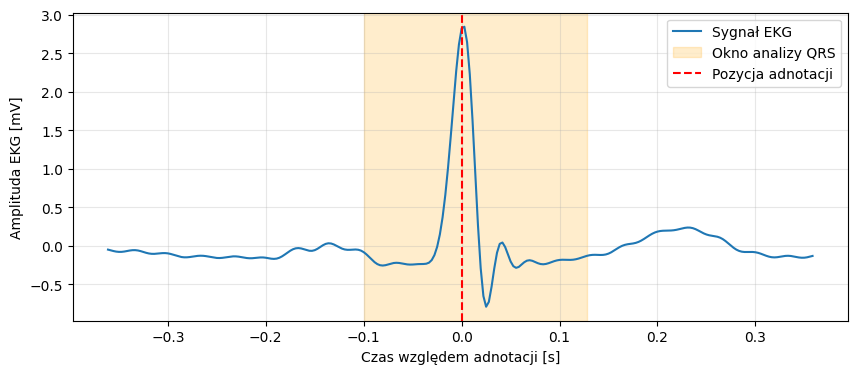

In [4]:
row = ds1_df.iloc[20678]

signal = row[signal_columns].to_numpy(dtype=float)
time = (np.arange(SEGMENT_LENGTH) - R_INDEX) / FS

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(time, signal, label='Sygnał EKG')

ax.axvspan(
    (QRS_START - R_INDEX) / FS,
    (QRS_END - R_INDEX) / FS,
    color='orange',
    alpha=0.2,
    label='Okno analizy QRS'
)

ax.axvline(
    0,
    color='red',
    linestyle='--',
    label='Pozycja adnotacji'
)

ax.set_xlabel('Czas względem adnotacji [s]')
ax.set_ylabel('Amplituda EKG [mV]')
ax.legend()
ax.grid(alpha=0.3)

plt.show()

In [5]:
ds1_df.columns

Index(['record_id', 'annotation_sample', 'type', 'class', 'anomaly', 'lead',
       'x_0', 'x_1', 'x_2', 'x_3',
       ...
       'x_250', 'x_251', 'x_252', 'x_253', 'x_254', 'x_255', 'x_256', 'x_257',
       'x_258', 'x_259'],
      dtype='str', length=266)

In [6]:
for dataset in [ds1_df, ds2_df]:
    assert all(col in dataset.columns for col in signal_columns)
    assert all(col in dataset.columns for col in id_columns)
    assert dataset['class'].isin(CLASSES).all()

assert set(ds1_df['record_id']).isdisjoint(
    set(ds2_df['record_id'])
)

print('DS1:', ds1_df.shape)
print('DS2:', ds2_df.shape)

DS1: (57549, 266)
DS2: (51902, 266)


In [7]:
def extract_features(data):
    features_df = data[id_columns].copy()
    signal_values = data[signal_columns].to_numpy(dtype=float)
    
    features_df['mean'] = np.mean(signal_values, axis=1)
    features_df['std'] = np.std(signal_values, axis=1)
    
    features_df['min'] = np.min(signal_values, axis=1)
    features_df['max'] = np.max(signal_values, axis=1)
    
    features_df['peak_to_peak'] = features_df['max'] - features_df['min']
    
    features_df['median'] = np.median(signal_values, axis=1)
    features_df['iqr'] = iqr(signal_values, axis=1)
    
    features_df['skew'] = skew(signal_values, axis=1)
    features_df['kurtosis'] = kurtosis(signal_values, axis=1)
    
    features_df['max_abs'] = np.max(
        np.abs(signal_values), axis=1
    )
    
    features_df['rms'] = np.sqrt(
        np.mean(signal_values**2, axis=1)
    )
    
    signal_diff = np.diff(signal_values, axis=1)
    
    features_df['waveform_length'] = np.sum(
        np.abs(signal_diff), axis=1
    )
    features_df['max_diff'] = np.max(
        np.abs(signal_diff), axis=1
    )
    
    qrs_segments = signal_values[:, QRS_START:QRS_END]
    
    baseline = np.median(
        signal_values[:, :50],
        axis=1
    )
    
    features_df['qrs_abs_area'] = (
        np.sum(
            np.abs(qrs_segments - baseline[:, None]),
            axis=1
        ) / FS
    )
    
    features_df['qrs_max_slope'] = np.max(
        np.abs(np.diff(qrs_segments, axis=1)),
        axis=1
    ) * FS #największa zmiana amplitudy pomiędzy dwiema kolejnymi próbkami w mV/s
    
    amplitude_offsets_ms = [-80, -40, 0, 40, 80]

    for offset_ms in amplitude_offsets_ms:
        idx = R_INDEX + round(offset_ms * FS / 1000)

        name = (
            f'amp_m{abs(offset_ms)}'
            if offset_ms < 0
            else f'amp_p{offset_ms}'
        )

        features_df[name] = signal_values[:, idx]
        
    features_df['qrs_min'] = np.min(qrs_segments, axis=1)

    features_df['qrs_max'] = np.max(qrs_segments, axis=1)

    features_df['qrs_peak_to_peak'] = (
        features_df['qrs_max'] - features_df['qrs_min']
    )
    
    return features_df

In [8]:
ds1_features = extract_features(ds1_df)
ds2_features = extract_features(ds2_df)

print('DS1:', ds1_features.shape)
print('DS2:', ds2_features.shape)

DS1: (57549, 29)
DS2: (51902, 29)


In [9]:
new_features = [
    'amp_m80', 'amp_m40', 'amp_p0',
    'amp_p40', 'amp_p80',
    'qrs_min', 'qrs_max', 'qrs_peak_to_peak'
]

display(ds1_features[new_features].describe().T)

print(
    'Brakujące wartości:',
    ds1_features[new_features].isna().sum().sum()
)

,count,mean,std,min,25%,50%,75%,max
amp_m80,57549.0,-0.073138,0.096566,-3.200397,-0.115993,-0.070135,-0.030964,2.191166
amp_m40,57549.0,-0.000958,0.231083,-2.873013,-0.118472,-0.054269,0.072368,2.872712
amp_p0,57549.0,1.343960,0.845915,-3.177569,0.942172,1.399398,1.848618,4.010384
amp_p40,57549.0,-0.149691,0.419393,-2.716863,-0.317591,-0.138077,-0.001113,2.726785
amp_p80,57549.0,-0.184091,0.172111,-2.530681,-0.223124,-0.148457,-0.084319,2.022696
qrs_min,57549.0,-0.543764,0.362890,-3.250644,-0.736770,-0.455454,-0.256276,1.965060
qrs_max,57549.0,1.458813,0.665123,-0.872505,0.961370,1.455979,1.915040,4.052188
qrs_peak_to_peak,57549.0,2.002577,0.735046,0.025285,1.380788,1.910983,2.490589,4.786505


Brakujące wartości: 0


In [10]:
comparison = ds1_features.groupby(
    ds1_df['class']
)[new_features].median()

display(comparison.T.round(3))

class,F,N,Q,S,V
amp_m80,-0.125,-0.073,-0.067,-0.086,-0.027
amp_m40,0.357,-0.070,-0.037,-0.071,0.297
amp_p0,1.824,1.484,0.775,1.304,1.258
amp_p40,-0.150,-0.163,0.176,-0.139,-0.111
amp_p80,-0.329,-0.143,-0.220,-0.131,-0.237
qrs_min,-0.386,-0.439,-0.306,-0.580,-0.564
qrs_max,2.091,1.520,0.795,1.353,1.395
qrs_peak_to_peak,2.513,1.969,1.201,1.930,2.015


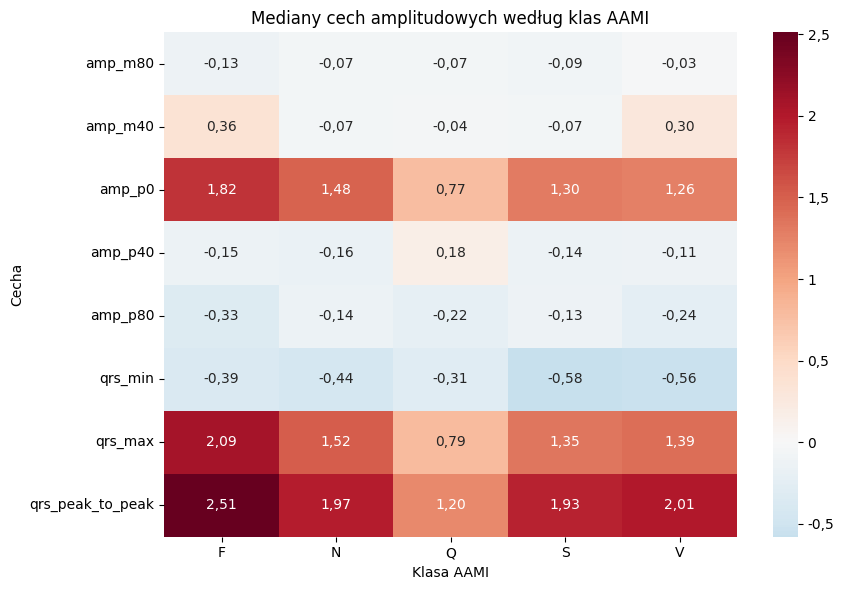

In [11]:
fig, ax = plt.subplots(figsize=(9, 6))

# Etykiety z przecinkami zamiast kropek
annotations = comparison.T.map(
    lambda x: f'{x:.2f}'.replace('.', ',')
)

heatmap = sns.heatmap(
    comparison.T,
    annot=annotations,
    fmt='',
    cmap='RdBu_r',
    center=0,
    ax=ax
)

# Formatowanie paska kolorów
cbar = heatmap.collections[0].colorbar
cbar.ax.yaxis.set_major_formatter(formatter)

ax.set_title('Mediany cech amplitudowych według klas AAMI')
ax.set_xlabel('Klasa AAMI')
ax.set_ylabel('Cecha')

plt.tight_layout()
plt.show()

klasy N i S z punktu widzenia median cech amplitudowych mają zbliżone charakterystyki. wartości dla cech amp_m40, amp_p40, qrs_peak_to_peak są niemal identyczne

poniżej obliczenie cech pochodzących z załamków R - odległości od poprzedniego, mediana kilku wcześniejszych oraz stosunek poprzedniego do lokalnej mediany. cechy mogą być wartościowe przy pobudzeniach przedwczesnych. wyznaczane korzystając z pliku adnotacji, ale tylko z uderzeń przeszłych; nie patrzymy w przyszłość

In [12]:

def calculate_rr_features(record_id):

    annotation_path = os.path.join(
        ANNOTATIONS_PATH,
        f'{record_id}_annotation.csv'
    )

    all_annotations = (
        pd.read_csv(annotation_path)
        .sort_values('Sample #')
    )

    # Tylko adnotacje uderzeń serca
    annotations = (
        all_annotations
        .dropna(subset=['AAMI'])
        .copy()
    )

    samples = annotations['Sample #'].to_numpy()

    # Poprzedni odstęp RR
    rr_prev = np.diff(
        samples.astype(float),
        prepend=np.nan
    ) / FS

    # Znaczniki epizodów trzepotania/migotania komór
    flutter_samples = np.sort(
        all_annotations.loc[
            all_annotations['Type'].isin(['[', '!', ']']),
            'Sample #'
        ].to_numpy()
    )

    if len(flutter_samples) > 0:

        prev_samples = np.r_[
            np.nan, samples[:-1]
        ]

        marker_count = (
            np.searchsorted(
                flutter_samples, samples, side='left'
            )
            -
            np.searchsorted(
                flutter_samples,
                np.nan_to_num(prev_samples, nan=-1),
                side='right'
            )
        )

        rr_prev[marker_count > 0] = np.nan

    annotations['rr_prev'] = rr_prev

    # Mediana maksymalnie 10 wcześniejszych RR
    annotations['rr_local_median'] = (
        annotations['rr_prev']
        .shift(1)
        .rolling(window=10, min_periods=5)
        .median()
    )

    annotations['rr_local_median'] = (
        annotations['rr_local_median']
        .where(lambda x: x > 0)
    )

    # Względny odstęp RR
    annotations['rr_prev_relative'] = (
        annotations['rr_prev']
        / annotations['rr_local_median']
    )

    return annotations[
        [
            'Sample #',
            'rr_prev',
            'rr_local_median',
            'rr_prev_relative'
        ]
    ].rename(columns={
        'Sample #': 'annotation_sample'
    })

In [13]:
record_ids = sorted(
    set(ds1_df['record_id'])
    | set(ds2_df['record_id'])
)

rr_features = []

for record_id in record_ids:
    record_rr = calculate_rr_features(record_id)
    record_rr['record_id'] = record_id
    rr_features.append(record_rr)

rr_df = pd.concat(rr_features, ignore_index=True)

print('Liczba rekordów:', len(record_ids))
print('Liczba wierszy RR:', len(rr_df))

display(rr_df.head(20))

Liczba rekordów: 48
Liczba wierszy RR: 109494


,annotation_sample,rr_prev,rr_local_median,rr_prev_relative,record_id
0,77,NaN,NaN,NaN,100
1,370,0.813889,NaN,NaN,100
2,662,0.811111,NaN,NaN,100
3,946,0.788889,NaN,NaN,100
4,1231,0.791667,NaN,NaN,100
5,1515,0.788889,NaN,NaN,100
6,1809,0.816667,0.791667,1.031579,100
7,2044,0.652778,0.801389,0.814558,100
8,2402,0.994444,0.791667,1.256140,100
9,2706,0.844444,0.801389,1.053726,100


In [14]:
rr_columns = [
    'rr_prev',
    'rr_local_median',
    'rr_prev_relative'
]

print('Brakujące wartości:')
print(rr_df[rr_columns].isna().sum())

print('\nStatystyki:')
display(rr_df[rr_columns].describe())

assert (rr_df['rr_prev'].dropna() > 0).all()
assert (rr_df['rr_local_median'].dropna() > 0).all()

assert not rr_df.duplicated(
    ['record_id', 'annotation_sample']
).any()

assert np.isfinite(
    rr_df[rr_columns].dropna().to_numpy()
).all()

Brakujące wartości:
rr_prev              54
rr_local_median     288
rr_prev_relative    294
dtype: int64

Statystyki:


,rr_prev,rr_local_median,rr_prev_relative
count,109440.000000,109206.000000,109200.000000
mean,0.790126,0.782222,1.015216
std,0.221941,0.177509,0.211299
min,0.250000,0.295833,0.256694
25%,0.655556,0.661111,0.965418
50%,0.763889,0.752778,0.999169
75%,0.891667,0.869444,1.034602
max,5.872222,2.170833,7.902804


In [15]:
long_rr = rr_df[
    rr_df['rr_prev'] > 2.0
].copy()

print('Liczba odstępów RR > 2 s:', len(long_rr))

display(
    long_rr.sort_values(
        'rr_prev', ascending=False
    ).head(20)
)

Liczba odstępów RR > 2 s: 135


,annotation_sample,rr_prev,rr_local_median,rr_prev_relative,record_id
102941,380595,5.872222,0.743056,7.902804,232
103284,512495,5.694444,0.731944,7.779886,232
103130,452324,5.616667,0.730556,7.688213,232
103562,613352,4.450000,0.743056,5.988785,232
103202,480081,4.447222,0.726389,6.122371,232
102986,398056,4.411111,0.740278,5.958724,232
103167,467366,4.377778,0.723611,6.049904,232
103344,534956,4.305556,0.745833,5.772812,232
102848,344483,4.202778,0.744444,5.645522,232
103227,490008,4.158333,0.743056,5.596262,232


In [16]:
long_rr.groupby('record_id').size().sort_values(
    ascending=False
)

record_id
232    116
201     13
219      3
207      2
208      1
dtype: int64

In [17]:
record_rr = rr_df[
    rr_df['record_id'] == 232
].sort_values('annotation_sample').reset_index(drop=True)

idx = record_rr['rr_prev'].idxmax()

display(
    record_rr.loc[
        max(0, idx - 3):idx + 3
    ]
)

,annotation_sample,rr_prev,rr_local_median,rr_prev_relative,record_id
1056,377934,0.727778,0.743056,0.979439,232
1057,378206,0.755556,0.733333,1.030303,232
1058,378481,0.763889,0.743056,1.028037,232
1059,380595,5.872222,0.743056,7.902804,232
1060,381024,1.191667,0.752778,1.583026,232
1061,381283,0.719444,0.752778,0.955720,232
1062,381559,0.766667,0.752778,1.018450,232


In [18]:
def add_rr_features(features_df, source_df):

    result = source_df[
        ['record_id', 'annotation_sample']
    ].copy()

    result = result.merge(
        rr_df,
        on=['record_id', 'annotation_sample'],
        how='left',
        validate='one_to_one',
        sort=False
    )

    rr_columns = [
        'rr_prev',
        'rr_local_median',
        'rr_prev_relative'
    ]

    assert len(result) == len(features_df)

    return pd.concat(
        [
            features_df.reset_index(drop=True),
            result[rr_columns].reset_index(drop=True)
        ],
        axis=1
    )

In [19]:
ds1_features = add_rr_features(
    ds1_features, ds1_df
)

ds2_features = add_rr_features(
    ds2_features, ds2_df
)

print('DS1:', ds1_features.shape)
print('DS2:', ds2_features.shape)

DS1: (57549, 32)
DS2: (51902, 32)


In [20]:
rr_columns = [
    'rr_prev',
    'rr_local_median',
    'rr_prev_relative'
]

assert len(ds1_features) == len(ds1_df)
assert len(ds2_features) == len(ds2_df)

print('Braki RR w DS1:')
print(ds1_features[rr_columns].isna().sum())

print('\nBraki RR w DS2:')
print(ds2_features[rr_columns].isna().sum())

Braki RR w DS1:
rr_prev              18
rr_local_median     137
rr_prev_relative    143
dtype: int64

Braki RR w DS2:
rr_prev              15
rr_local_median     130
rr_prev_relative    130
dtype: int64


In [21]:
rr_columns = [
    'rr_prev',
    'rr_local_median',
    'rr_prev_relative'
]

rr_comparison = (
    ds1_features
    .assign(beat_class=ds1_df['class'].to_numpy())
    .groupby('beat_class')[rr_columns]
    .median()
    .reindex(CLASSES)
)

display(rr_comparison.T.round(3))

beat_class,N,S,V,F,Q
rr_prev,0.756,0.494,0.519,0.586,0.819
rr_local_median,0.738,0.640,0.683,0.587,0.819
rr_prev_relative,1.004,0.797,0.750,0.993,1.002


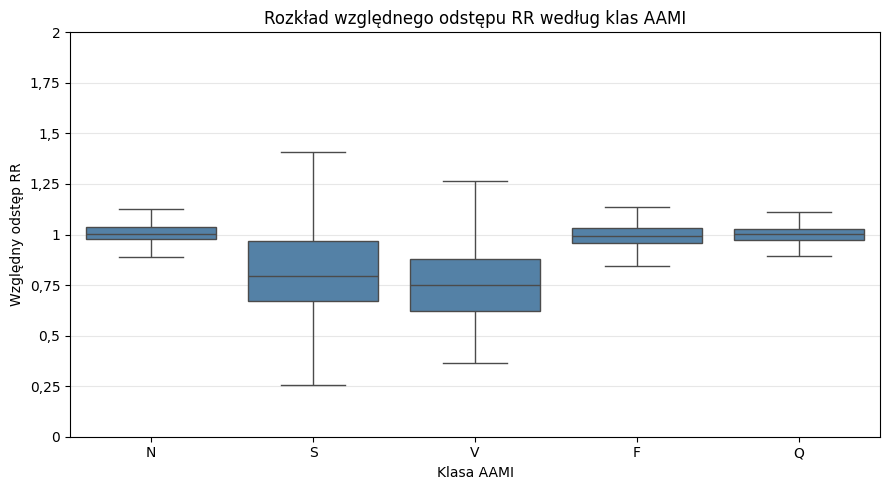

In [22]:
plot_df = ds1_features[['rr_prev_relative']].copy()
plot_df['class'] = ds1_df['class'].to_numpy()

fig, ax = plt.subplots(figsize=(9, 5))

sns.boxplot(
    data=plot_df,
    x='class',
    y='rr_prev_relative',
    order=CLASSES,
    color='steelblue',
    showfliers=False,
    ax=ax
)

ax.set_ylim(0, 2)
ax.set_title('Rozkład względnego odstępu RR według klas AAMI')
ax.set_xlabel('Klasa AAMI')
ax.set_ylabel('Względny odstęp RR')

ax.yaxis.set_major_formatter(formatter)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## Analiza korelacji

In [23]:
metadata_columns = [
    'record_id',
    'annotation_sample',
    'type',
    'class',
    'anomaly',
    'lead'
]

feature_columns = [
    col for col in ds1_features.columns
    if col not in metadata_columns
]

print(feature_columns)
print('Liczba cech:', len(feature_columns))

correlation_matrix = ds1_features[
    feature_columns
].corr(method='spearman')

['mean', 'std', 'min', 'max', 'peak_to_peak', 'median', 'iqr', 'skew', 'kurtosis', 'max_abs', 'rms', 'waveform_length', 'max_diff', 'qrs_abs_area', 'qrs_max_slope', 'amp_m80', 'amp_m40', 'amp_p0', 'amp_p40', 'amp_p80', 'qrs_min', 'qrs_max', 'qrs_peak_to_peak', 'rr_prev', 'rr_local_median', 'rr_prev_relative']
Liczba cech: 26


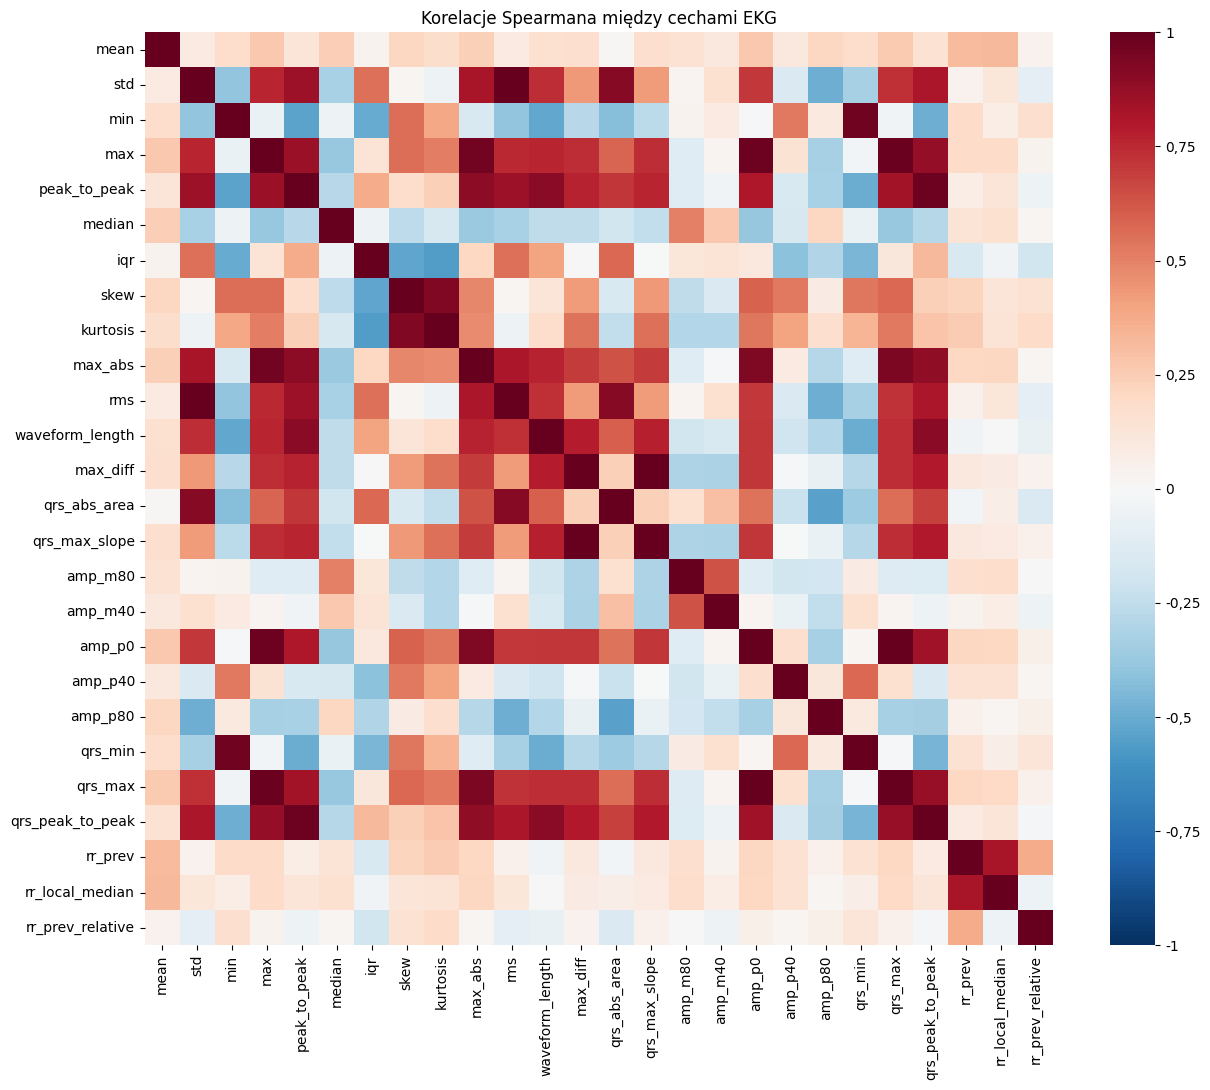

In [24]:
fig, ax = plt.subplots(figsize=(13, 11))

sns.heatmap(
    correlation_matrix,
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    ax=ax
)

ax.set_title('Korelacje Spearmana między cechami EKG')

cbar = ax.collections[0].colorbar
cbar.ax.yaxis.set_major_formatter(formatter)

plt.tight_layout()
plt.show()

In [25]:
upper = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
)

strong_correlations = (
    upper.stack()
    .loc[lambda x: x.abs() >= 0.9]
    .sort_values(key=abs, ascending=False)
)

display(strong_correlations)

std              rms                 0.999410
max_diff         qrs_max_slope       0.997803
amp_p0           qrs_max             0.993920
max              qrs_max             0.990686
peak_to_peak     qrs_peak_to_peak    0.983255
max              amp_p0              0.981921
min              qrs_min             0.971548
max              max_abs             0.964489
max_abs          qrs_max             0.945044
                 amp_p0              0.933607
skew             kurtosis            0.923729
rms              qrs_abs_area        0.910591
std              qrs_abs_area        0.910057
peak_to_peak     waveform_length     0.904718
waveform_length  qrs_peak_to_peak    0.901318
dtype: float64

In [26]:
redundant_features = [
    'rms',
    'max_diff',
    'max',
    'min',
    'peak_to_peak'
]

reduced_feature_columns = [
    col for col in feature_columns
    if col not in redundant_features
]

print('Liczba wszystkich cech:', len(feature_columns))
print('Liczba cech po redukcji:', len(reduced_feature_columns))

Liczba wszystkich cech: 26
Liczba cech po redukcji: 21


In [27]:
analysis_df = ds1_features.copy()

class_medians = (
    analysis_df
    .groupby('class')[reduced_feature_columns]
    .median()
    .reindex(CLASSES)
)

display(class_medians.T.round(3))

class,N,S,V,F,Q
mean,0.005,0.006,0.010,-0.012,-0.010
std,0.319,0.265,0.528,0.460,0.196
median,-0.051,-0.042,-0.066,-0.116,-0.044
iqr,0.173,0.193,0.445,0.218,0.122
skew,3.224,2.662,1.114,2.835,1.980
kurtosis,11.877,10.752,1.351,9.205,4.365
max_abs,1.527,1.372,1.503,2.096,0.798
waveform_length,5.609,6.022,5.721,6.225,3.274
qrs_abs_area,0.067,0.066,0.138,0.116,0.053
qrs_max_slope,110.290,135.941,74.098,130.006,69.130


In [28]:
class_iqr = (
    analysis_df
    .groupby('class')[reduced_feature_columns]
    .agg(
        lambda x: x.quantile(0.75) - x.quantile(0.25)
    )
    .reindex(CLASSES)
)

display(class_iqr.T.round(3))

class,N,S,V,F,Q
mean,0.024,0.056,0.077,0.026,0.020
std,0.155,0.129,0.232,0.148,0.037
median,0.047,0.082,0.108,0.041,0.026
iqr,0.106,0.100,0.323,0.152,0.070
skew,2.243,2.575,1.457,1.520,2.538
kurtosis,11.110,10.465,1.582,9.689,3.082
max_abs,0.867,0.463,1.007,0.254,0.128
waveform_length,2.941,3.175,3.573,0.497,0.486
qrs_abs_area,0.038,0.053,0.094,0.049,0.009
qrs_max_slope,80.611,88.563,58.807,23.469,6.602


In [29]:
results = []

for feature in reduced_feature_columns:
    valid = ds1_features[[feature, 'anomaly']].dropna()

    r, p = pointbiserialr(
        valid['anomaly'],
        valid[feature]
    )

    results.append({
        'feature': feature,
        'correlation': r,
        'abs_correlation': abs(r),
        'p_value': p
    })

binary_correlations = (
    pd.DataFrame(results)
    .sort_values('abs_correlation', ascending=False)
)

display(binary_correlations)

,feature,correlation,abs_correlation,p_value
5,kurtosis,-0.386803,0.386803,0.000000e+00
13,amp_p40,0.335113,0.335113,0.000000e+00
20,rr_prev_relative,-0.309723,0.309723,0.000000e+00
4,skew,-0.300435,0.300435,0.000000e+00
11,amp_m40,0.263335,0.263335,0.000000e+00
3,iqr,0.256877,0.256877,0.000000e+00
9,qrs_max_slope,-0.252936,0.252936,0.000000e+00
18,rr_prev,-0.250166,0.250166,0.000000e+00
8,qrs_abs_area,0.233531,0.233531,0.000000e+00
12,amp_p0,-0.214177,0.214177,0.000000e+00


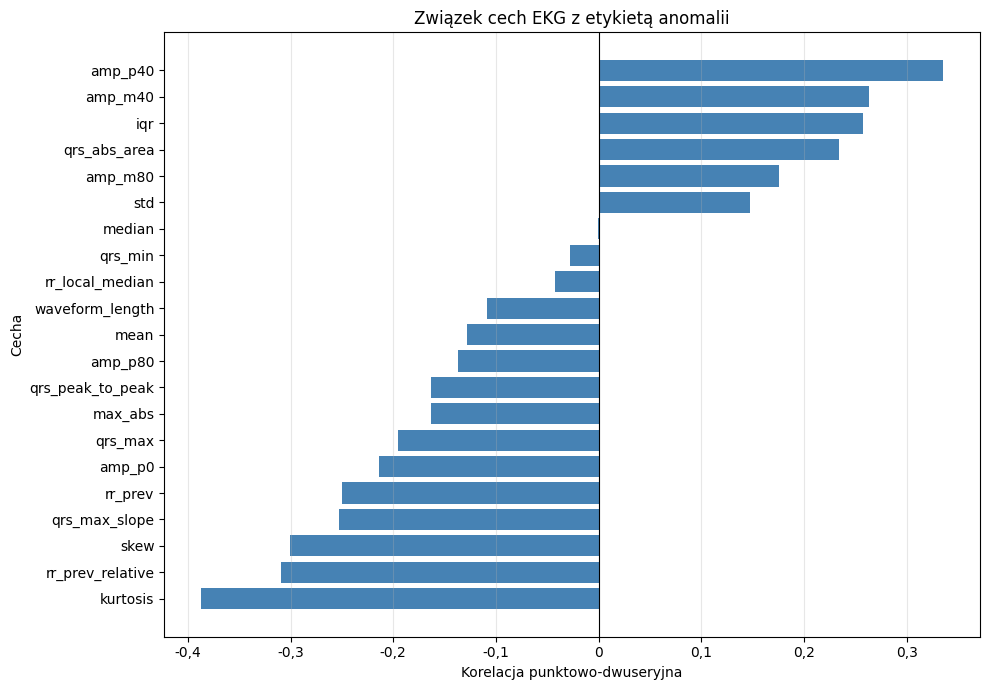

In [30]:
fig, ax = plt.subplots(figsize=(10, 7))

ordered = binary_correlations.sort_values('correlation')

ax.barh(
    ordered['feature'],
    ordered['correlation'],
    color='steelblue'
)

ax.axvline(0, color='black', linewidth=0.8)

ax.set_xlabel('Korelacja punktowo-dwuseryjna')
ax.set_ylabel('Cecha')
ax.set_title('Związek cech EKG z etykietą anomalii')

ax.xaxis.set_major_formatter(formatter)
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

In [31]:
results = []

for feature in reduced_feature_columns:

    groups = [
        ds1_features.loc[
            ds1_features['class'] == cls, feature
        ].dropna().to_numpy()
        for cls in CLASSES
    ]

    H, p = kruskal(*groups)

    n = sum(len(g) for g in groups)
    k = len(groups)

    epsilon_sq = max(0, (H - k + 1) / (n - k))

    results.append({
        'feature': feature,
        'H': H,
        'epsilon_squared': epsilon_sq,
        'p_value': p
    })

multiclass_results = (
    pd.DataFrame(results)
    .sort_values('epsilon_squared', ascending=False)
)

display(multiclass_results)

,feature,H,epsilon_squared,p_value
5,kurtosis,12375.638043,0.214994,0.000000e+00
3,iqr,9987.742147,0.173498,0.000000e+00
1,std,9692.422154,0.168365,0.000000e+00
18,rr_prev,8774.733640,0.152466,0.000000e+00
20,rr_prev_relative,8588.510872,0.149553,0.000000e+00
7,waveform_length,7382.443679,0.128223,0.000000e+00
6,max_abs,7295.003846,0.126703,0.000000e+00
8,qrs_abs_area,7073.640750,0.122856,0.000000e+00
4,skew,6690.109227,0.116191,0.000000e+00
17,qrs_peak_to_peak,6539.824608,0.113580,0.000000e+00


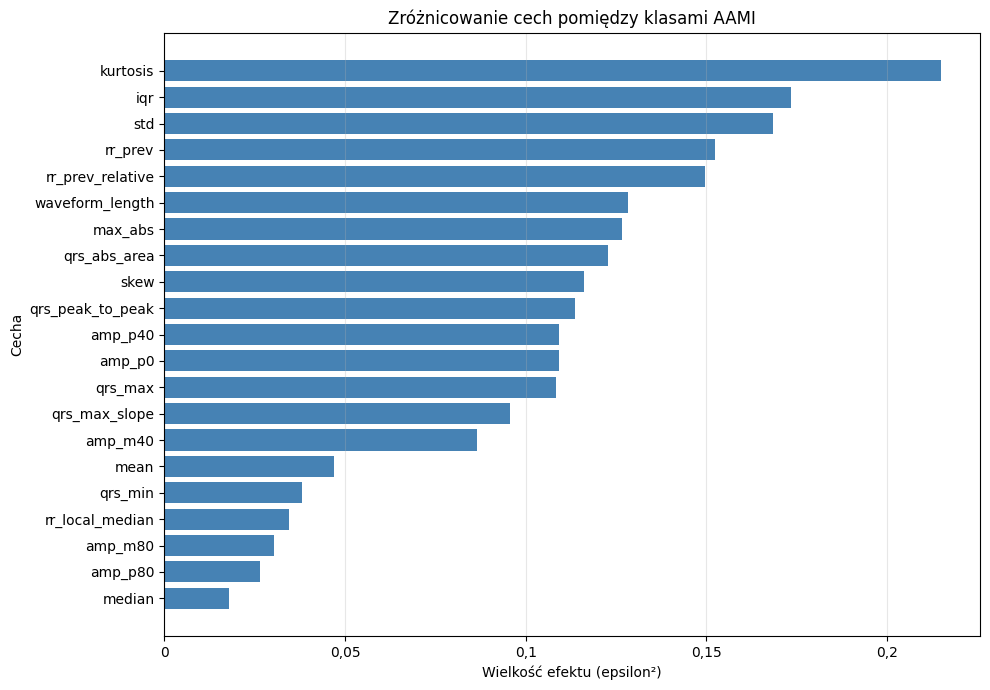

In [32]:
fig, ax = plt.subplots(figsize=(10, 7))

ordered = multiclass_results.sort_values('epsilon_squared')

ax.barh(
    ordered['feature'],
    ordered['epsilon_squared'],
    color='steelblue'
)

ax.set_title('Zróżnicowanie cech pomiędzy klasami AAMI')
ax.set_xlabel('Wielkość efektu (epsilon²)')
ax.set_ylabel('Cecha')

ax.xaxis.set_major_formatter(formatter)
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

In [33]:
assert ds1_features.columns.equals(ds2_features.columns)

assert len(ds1_features) == len(ds1_df)
assert len(ds2_features) == len(ds2_df)

assert set(feature_columns).issubset(ds1_features.columns)
assert set(feature_columns).issubset(ds2_features.columns)

print('Liczba cech:', len(feature_columns))
print('DS1:', ds1_features.shape)
print('DS2:', ds2_features.shape)

Liczba cech: 26
DS1: (57549, 32)
DS2: (51902, 32)


In [34]:
ds1_features.to_csv(
    '../src/ds1_features.csv',
    index=False
)

ds2_features.to_csv(
    '../src/ds2_features.csv',
    index=False
)